# 03 · Results analysis: how well does the model work as a laser weeder?

Works from the saved outputs of one run only (`results.json`, `train/results.csv`,
`eval/predictions.jsonl`, `eval/visualizations/`), so it runs on your PC after you download the
Kaggle results. The test images themselves are **not** needed.

For CropAndWeed, sections 6–8 also read the official annotations in `data/raw/cropandweed_src`
(`bboxes/` and `labelIds/`, which cover all 8,034 images even with only 1/4 of the images
downloaded). They tell us exactly what each laser shot landed on: weed, crop species, or soil.

**Reading guide.** A *shot* = one laser point fired at one predicted weed (after the crop safety
gate). The three numbers that matter for a weeder:

| Metric | Meaning | Want |
|---|---|---|
| `weed_hit_rate` | share of real weeds that got a shot inside them | high |
| `shot_precision` | share of shots that landed on a weed | high (else laser time is wasted) |
| `crop_hit_rate` | share of shots that landed on a crop | ≈ 0 (each one damages the crop) |

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.utils.io import load_json, read_jsonl

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)

RUN_DIR = Path("experiments/yolo11s_seg_cropandweed")
SOURCE_DIR = Path("data/raw/cropandweed_src")   # official CropAndWeed annotations (sections 6-8); missing = skipped
METHOD = None                                    # targeting method to analyse; None = the run's primary method

results = load_json(RUN_DIR / "results.json")
records = read_jsonl(RUN_DIR / "eval" / "predictions.jsonl")
history = pd.read_csv(RUN_DIR / "train" / "results.csv")
history.columns = history.columns.str.strip()
tgt = results["targeting"]
METHOD = METHOD or tgt["primary_method"]
has_source = (SOURCE_DIR / "bboxes").exists() and (SOURCE_DIR / "labelIds").exists()
print(f"{results['experiment']['name']}: {len(records)} test images, method = {METHOD}, "
      f"conf = {tgt['conf']}, crop margin = {tgt.get('crop_margin_px')} px, source annotations: {has_source}")

yolo11s_seg_cropandweed: 1201 test images, method = center_weighted_dt, conf = 0.25, crop margin = 20.0 px, source annotations: True


## 1. Headline: what happens to 100 shots and 100 weeds

In [2]:
m = tgt["methods"][METHOD]
shots = sum(r["methods"][METHOD]["shots"] for r in records)
on_weed = sum(r["methods"][METHOD]["shots_on_weed"] for r in records)
crop_hits = sum(r["methods"][METHOD]["crop_hits"] for r in records)
print(f"Per 100 shots : {100 * on_weed / shots:5.1f} on a weed | {100 * crop_hits / shots:4.1f} on a crop | "
      f"{100 * (shots - on_weed - crop_hits) / shots:4.1f} elsewhere (soil, unlabelled plants)")
print(f"Per 100 weeds : {100 * m['weed_hit_rate']:5.1f} destroyed | {100 * (1 - m['weed_hit_rate']):4.1f} survive")
print(f"Safety gate   : crop hits {100 * m['crop_hit_rate_ungated']:.1f}% -> {100 * m['crop_hit_rate']:.1f}% of shots, "
      f"at the cost of {100 * m['veto_rate']:.1f}% of shots not fired")
print(f"Speed         : {tgt['end_to_end_ms_per_image']:.0f} ms/image end to end ({1000 / tgt['end_to_end_ms_per_image']:.0f} FPS) "
      f"on {results['environment'].get('gpu_name', 'the eval GPU')}")

Per 100 shots :  80.6 on a weed |  2.2 on a crop | 17.2 elsewhere (soil, unlabelled plants)
Per 100 weeds :  71.9 destroyed | 28.1 survive
Safety gate   : crop hits 3.3% -> 2.2% of shots, at the cost of 2.7% of shots not fired
Speed         : 39 ms/image end to end (26 FPS) on Tesla T4


## 2. Training: did it learn, did it overfit?

Train and val losses falling together = still learning; val loss rising while train loss falls =
overfitting. The dashed line is the epoch whose weights (`best.pt`) are evaluated.

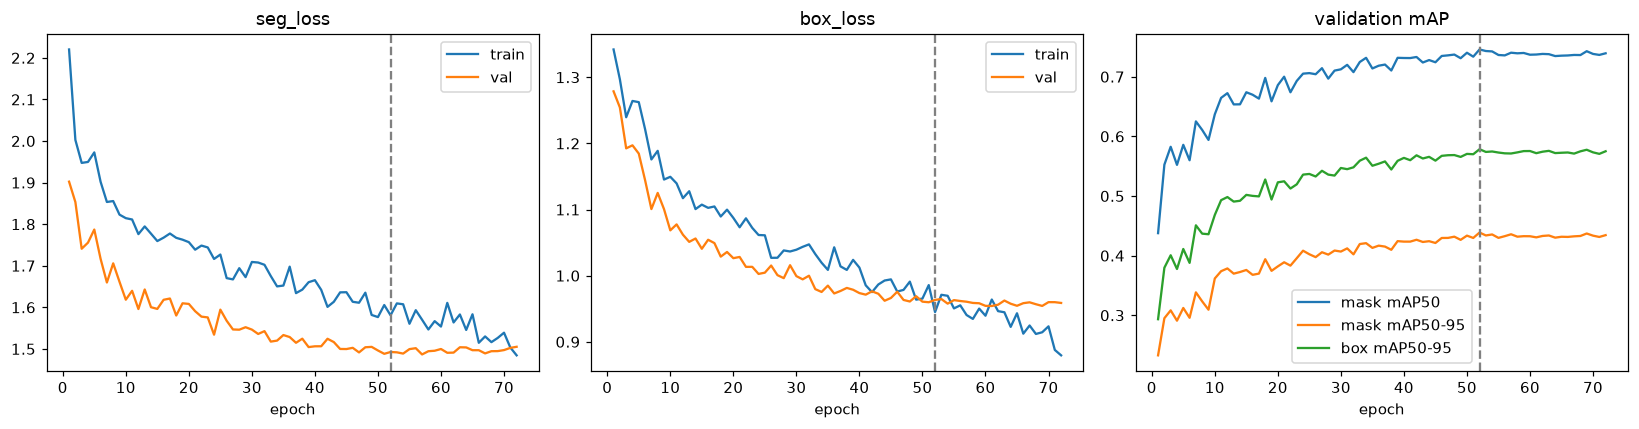

best epoch 52, stopped at 72 (patience); val mask mAP50-95 over the last 10 epochs: 0.430-0.437 (plateau)


In [3]:
best = results["training"]["best_epoch"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, loss in zip(axes[:2], ["seg_loss", "box_loss"]):
    ax.plot(history["epoch"], history[f"train/{loss}"], label="train")
    ax.plot(history["epoch"], history[f"val/{loss}"], label="val")
    ax.set_title(loss); ax.legend()
for col, label in [("metrics/mAP50(M)", "mask mAP50"), ("metrics/mAP50-95(M)", "mask mAP50-95"), ("metrics/mAP50-95(B)", "box mAP50-95")]:
    axes[2].plot(history["epoch"], history[col], label=label)
axes[2].set_title("validation mAP"); axes[2].legend()
for ax in axes:
    ax.axvline(best, ls="--", c="grey"); ax.set_xlabel("epoch")
plt.tight_layout(); plt.show()
last10 = history.tail(10)["metrics/mAP50-95(M)"]
print(f"best epoch {best}, stopped at {results['training']['epochs_completed']} (patience); "
      f"val mask mAP50-95 over the last 10 epochs: {last10.min():.3f}-{last10.max():.3f} (plateau)")

## 3. Segmentation quality per class (test split)

mAP50 = the mask overlaps the true plant by at least 50 %; mAP50-95 also rewards precise outlines.

In [4]:
seg = results["segmentation"]
display(pd.DataFrame({"box": seg["box"], "mask": seg["mask"]}).T)
display(pd.DataFrame(seg["per_class_mask"]).T)
splits = pd.DataFrame({s: v["instances_per_class"] | {"images": v["num_images"]} for s, v in results["dataset"]["splits"].items()}).T
display(splits)

,precision,recall,map50,map50_95
box,0.786,0.760,0.804,0.580
mask,0.758,0.714,0.746,0.419


,map50,map50_95
Crop,0.880,0.574
Weed,0.612,0.265


,Crop,Weed,images
train,13099,38683,5224
val,4111,12293,1609
test,3555,6547,1201


## 4. Targeting methods compared

All methods get the same predicted masks; they only differ in *where inside the mask* the point
goes. `clearance` = distance from the point to the weed's edge (bigger = more aiming error
tolerated); `off_center_rate` = share of points more than half a radius from the plant centre.

,weed_hit_rate,shot_precision,crop_hit_rate,clearance_px (median),clearance_px (p10),off_center_rate,ms/img
center_weighted_dt,0.719,0.806,0.022,5.0,1.4,0.074,6.330
distance_transform,0.717,0.805,0.021,5.0,1.4,0.371,3.999
skeleton,0.710,0.793,0.021,4.2,1.0,0.055,16.888
centroid,0.662,0.734,0.020,4.0,0.0,0.049,3.564
box_center,0.616,0.675,0.019,3.6,0.0,0.129,3.673


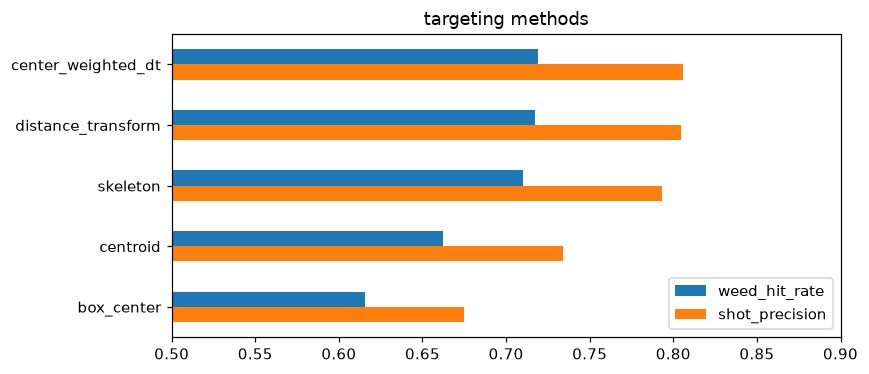

In [5]:
rows = {}
for name, v in tgt["methods"].items():
    rows[name] = {"weed_hit_rate": v["weed_hit_rate"], "shot_precision": v["shot_precision"], "crop_hit_rate": v["crop_hit_rate"],
                  "clearance_px (median)": v["clearance_px"]["median"], "clearance_px (p10)": v["clearance_px"]["p10"],
                  "off_center_rate": v["off_center_rate"], "ms/img": v["extraction_ms_per_image"]}
methods_df = pd.DataFrame(rows).T.sort_values("weed_hit_rate", ascending=False)
display(methods_df)
methods_df[["weed_hit_rate", "shot_precision"]].plot.barh(figsize=(8, 3.5), xlim=(0.5, 0.9), title="targeting methods")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

## 5. Per-image table and the two image sets

CropAndWeed has two sets: **ave** (Application set: real fields) and **vwg** (Experimental set:
test plots). Image names start with the set and the recording session (`ave-0543-0014` → session
`ave-0543`).

In [6]:
def image_row(r):
    mm = r["methods"][METHOD]
    return {"image": r["image_id"], "set": r["image_id"][:3], "session": r["image_id"][:8],
            "gt_weeds": r["num_gt"], "gt_crops": r["num_gt_crops"], "pred_crops": r["num_pred_crops"],
            "shots": mm["shots"], "shots_on_weed": mm["shots_on_weed"], "weeds_hit": mm["weeds_hit"],
            "crop_hits": mm["crop_hits"], "crop_hits_ungated": mm["crop_hits_ungated"], "vetoed": len(mm["vetoed_preds"])}

img = pd.DataFrame([image_row(r) for r in records])

def rates(g):
    s = g.sum(numeric_only=True)
    return pd.Series({"images": len(g), "gt_weeds": s.gt_weeds, "gt_crops": s.gt_crops, "shots": s.shots,
                      "weed_hit_rate": s.weeds_hit / max(s.gt_weeds, 1), "shot_precision": s.shots_on_weed / max(s.shots, 1),
                      "crop_hit_rate": s.crop_hits / max(s.shots, 1),
                      "crop_hit_rate_ungated": s.crop_hits_ungated / max(s.shots + s.vetoed, 1)})

display(img.groupby("set").apply(rates, include_groups=False))

,images,gt_weeds,gt_crops,shots,weed_hit_rate,shot_precision,crop_hit_rate,crop_hit_rate_ungated
set,,,,,,,,
ave,442.0,1521.0,2359.0,1307.0,0.592,0.712,0.080,0.113
vwg,759.0,5026.0,1196.0,5081.0,0.757,0.830,0.007,0.012


## 6. Where do the shots land? (needs `SOURCE_DIR`)

Each fired point is looked up in the official species mask: weed, crop (and which crop species),
bare soil, or a plant outside the two classes.

,share of shots,shots
kind,,
weed,0.800,5108
soil,0.177,1131
crop,0.022,140
other plant,0.001,9


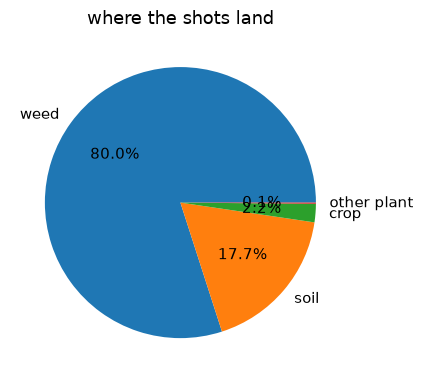

In [7]:
import csv

from src.data.cropandweed import map_label

def source_boxes(stem):
    with open(SOURCE_DIR / "bboxes" / f"{stem}.csv", newline="") as f:
        return [tuple(int(v) for v in row) for row in csv.reader(f) if row]

def fired_points(r):
    mm = r["methods"][METHOD]
    skip = set(r["ignored_preds"]) | set(mm["vetoed_preds"])
    return [(i, p) for i, p in enumerate(mm["pred_points"]) if i not in skip and p is not None]

shot_rows, weed_rows, crop_rows = [], [], []
if has_source:
    for r in records:
        species = cv2.imread(str(SOURCE_DIR / "labelIds" / "CropAndWeed" / f"{r['image_id']}.png"), cv2.IMREAD_GRAYSCALE)
        h, w = species.shape
        fired = fired_points(r)
        for i, (x, y) in fired:
            sid = int(species[min(int(round(y)), h - 1), min(int(round(x)), w - 1)])
            cls = map_label(sid) if sid else None
            kind = "soil" if sid == 0 else {0: "crop", 1: "weed"}.get(cls, "other plant")
            shot_rows.append({"image": r["image_id"], "kind": kind, "species": sid, "conf": r["pred_confidences"][i]})
        matched = {g for _, g, _ in r["matches"]}
        boxes = source_boxes(r["image_id"])
        weeds = [b for b in boxes if map_label(b[4]) == 1]   # same order as the GT weeds in predictions.jsonl
        for g, (left, top, right, bottom, sid, *_ ) in enumerate(weeds):
            hit = any(left <= x <= right and top <= y <= bottom for _, (x, y) in fired)
            weed_rows.append({"image": r["image_id"], "species": sid, "size_px": np.sqrt((right - left) * (bottom - top)),
                              "matched": g in matched, "hit": hit})
        for left, top, right, bottom, sid, *_ in (b for b in boxes if map_label(b[4]) == 0):
            crop_rows.append({"image": r["image_id"], "species": sid})
    shots_df, weeds_df, crops_df = pd.DataFrame(shot_rows), pd.DataFrame(weed_rows), pd.DataFrame(crop_rows)
    landing = shots_df["kind"].value_counts()
    display((landing / landing.sum()).rename("share of shots").to_frame().assign(shots=landing))
    landing.plot.pie(autopct="%1.1f%%", figsize=(4, 4), ylabel="", title="where the shots land"); plt.show()
else:
    print(f"{SOURCE_DIR} not found: sections 6-8 skipped")

**Soil shots: can a higher confidence threshold remove them?** If soil shots had clearly lower
confidence than weed shots, raising `eval.conf` would remove them cheaply.

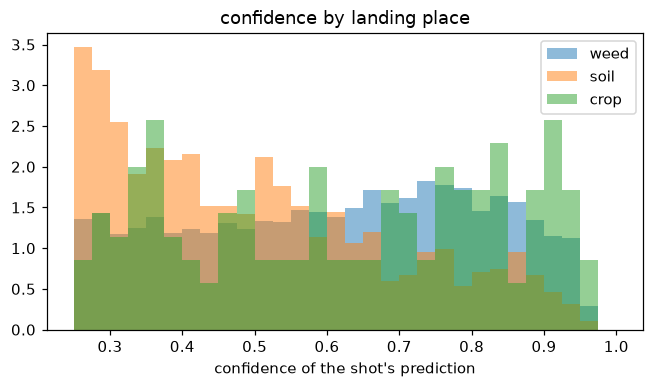

conf >= 0.25: weed shots  5108  soil shots  1131  crop shots  140
conf >= 0.35: weed shots  4441  soil shots   817  crop shots  121
conf >= 0.50: weed shots  3479  soil shots   508  crop shots   92
conf >= 0.60: weed shots  2767  soil shots   323  crop shots   76


In [8]:
if has_source:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for kind in ["weed", "soil", "crop"]:
        ax.hist(shots_df.loc[shots_df.kind == kind, "conf"], bins=30, range=(0.25, 1), alpha=0.5, density=True, label=kind)
    ax.set_xlabel("confidence of the shot's prediction"); ax.legend(); ax.set_title("confidence by landing place"); plt.show()
    for th in [0.25, 0.35, 0.5, 0.6]:
        kept = shots_df[shots_df.conf >= th]["kind"].value_counts()
        print(f"conf >= {th:.2f}: weed shots {kept.get('weed', 0):5d}  soil shots {kept.get('soil', 0):5d}  crop shots {kept.get('crop', 0):4d}")

## 7. Which weeds survive? Size and species (needs `SOURCE_DIR`)

Size = square root of the weed's box area in pixels of the 1920×1088 image (≈ 0.4 mm/px, so
25 px ≈ 1 cm). During training and inference the image is shrunk to `imgsz` = 1024 px wide,
so every plant is drawn about 1.9× smaller for the network.

,weeds,hit_rate,share_of_all_misses
size,,,
"(0, 16]",41,0.341,0.021
"(16, 24]",1550,0.606,0.466
"(24, 32]",1162,0.825,0.155
"(32, 48]",1285,0.863,0.135
"(48, 64]",689,0.862,0.073
"(64, 128]",1068,0.875,0.102
"(128, 2000]",752,0.916,0.048


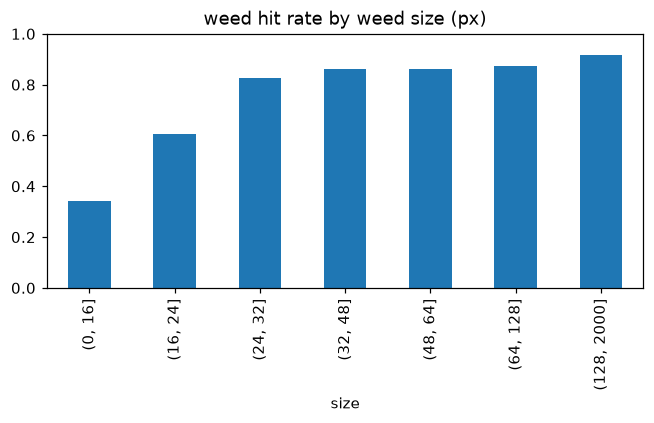

,weeds,hit_rate
species,,
69,1163,0.800
35,627,0.762
32,599,0.563
33,430,0.819
70,416,0.825
72,274,0.927
80,259,0.919
71,250,0.880
36,230,0.865


In [9]:
if has_source:
    weeds_df["size"] = pd.cut(weeds_df.size_px, [0, 16, 24, 32, 48, 64, 128, 2000])
    by_size = weeds_df.groupby("size", observed=True).agg(weeds=("hit", "size"), hit_rate=("hit", "mean"))
    by_size["share_of_all_misses"] = weeds_df[~weeds_df.hit].groupby("size", observed=True).size() / (~weeds_df.hit).sum()
    display(by_size)
    by_size["hit_rate"].plot.bar(figsize=(7, 3), ylim=(0, 1), title="weed hit rate by weed size (px)"); plt.show()
    by_species = weeds_df.groupby("species").agg(weeds=("hit", "size"), hit_rate=("hit", "mean")).sort_values("weeds", ascending=False)
    display(by_species.head(12))

## 8. Crop hits: which crops, where, and why the gate didn't stop them (needs `SOURCE_DIR`)

The gate only protects crops the model *recognised as crops*. If a crop is predicted as a weed,
no crop mask exists to veto the shot, so the crop itself becomes the target.

In [10]:
if has_source:
    crop_shots = shots_df[shots_df.kind == "crop"]
    per_species = pd.DataFrame({"crops_in_test": crops_df.species.value_counts(), "crop_shots": crop_shots.species.value_counts()}).fillna(0).astype(int)
    per_species["shots_per_crop"] = per_species.crop_shots / per_species.crops_in_test
    display(per_species.sort_values("crop_shots", ascending=False).head(10))

by_session = img.groupby("session").sum(numeric_only=True).sort_values("crop_hits", ascending=False)
top = by_session.head(8)[["gt_weeds", "gt_crops", "pred_crops", "shots", "crop_hits", "crop_hits_ungated"]]
display(top)
print(f"top 3 sessions = {top.crop_hits.head(3).sum() / img.crop_hits.sum():.0%} of all crop hits")
under = img.pred_crops < img.gt_crops
print(f"crop hits in images where the model found FEWER crops than there are: {img[under].crop_hits.sum()} "
      f"of {img.crop_hits.sum()}  -> missed/misclassified crops, which the gate cannot protect")

,crops_in_test,crop_shots,shots_per_crop
species,,,
24,187,54,0.289
94,1061,33,0.031
7,232,10,0.043
1,766,9,0.012
9,315,8,0.025
13,168,8,0.048
10,256,6,0.023
4,36,5,0.139
18,13,3,0.231


,gt_weeds,gt_crops,pred_crops,shots,crop_hits,crop_hits_ungated
session,,,,,,
ave-0543,0,477,504,33,32,48
ave-0153,9,36,6,38,31,34
ave-0284,25,104,86,59,25,32
vwg-0328,43,78,70,52,8,8
vwg-0589,28,144,138,39,8,12
vwg-0018,86,39,26,103,7,15
vwg-1327,68,25,17,66,5,5
ave-0199,9,84,92,26,3,9


top 3 sessions = 62% of all crop hits
crop hits in images where the model found FEWER crops than there are: 133 of 141  -> missed/misclassified crops, which the gate cannot protect


## 9. Confidence threshold trade-off

Re-thresholds the saved predictions (only *upwards* from the evaluation's `conf`). A prediction
counts as correct when its mask matches a GT weed with IoU ≥ 0.5, a stricter test than "the point
hit the weed", so these values are below `shot_precision` / `weed_hit_rate` but show the trend.

conf,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80
precision@IoU.5,0.616,0.652,0.679,0.711,0.734,0.763,0.796,0.820,0.857,0.886,0.903,0.927
recall@IoU.5,0.617,0.596,0.573,0.547,0.515,0.484,0.447,0.401,0.359,0.306,0.243,0.178


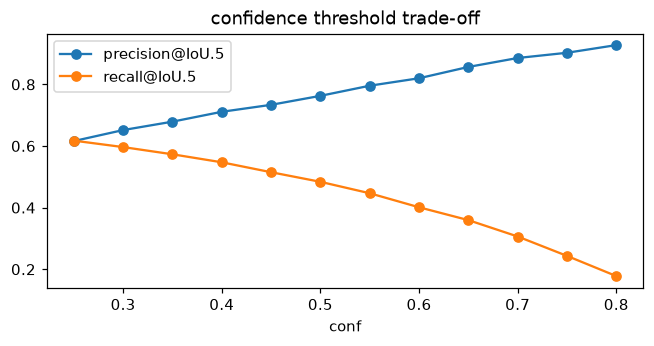

In [11]:
num_gt = sum(r["num_gt"] for r in records)
rows = []
for th in np.arange(tgt["conf"], 0.81, 0.05):
    tp = fp = 0
    for r in records:
        matched = {p for p, _, _ in r["matches"]}
        keep = [i for i, c in enumerate(r["pred_confidences"]) if c >= th and i not in r["ignored_preds"]]
        tp += sum(i in matched for i in keep); fp += len(keep) - sum(i in matched for i in keep)
    rows.append({"conf": round(th, 2), "precision@IoU.5": tp / max(tp + fp, 1), "recall@IoU.5": tp / num_gt})
sweep = pd.DataFrame(rows).set_index("conf")
display(sweep.T)
sweep.plot(marker="o", figsize=(7, 3), title="confidence threshold trade-off"); plt.show()

## 10. Aiming: how much room does the point leave?

`clearance_px` for weeds that were matched: distance from the shot to the weed's edge. A laser
spot plus aiming error larger than this misses the weed (and can hit a neighbour).

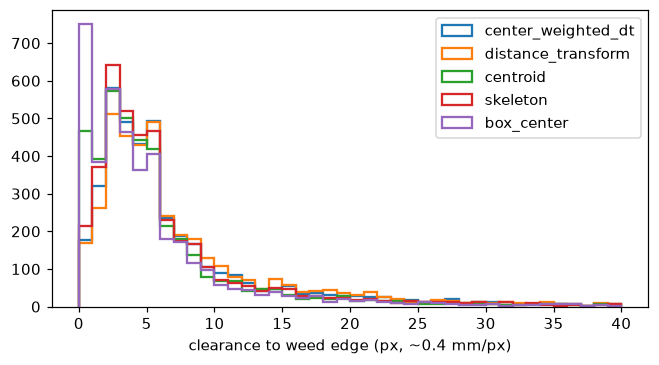

center_weighted_dt: median clearance 5.0 px (~2.0 mm); 50% of shots are < 5 px (~2 mm) from the weed's edge


In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name in tgt["methods"]:
    values = [c for r in records for c in r["methods"][name]["clearance_px"]]
    ax.hist(values, bins=40, range=(0, 40), histtype="step", lw=1.5, label=name)
ax.set_xlabel("clearance to weed edge (px, ~0.4 mm/px)"); ax.legend(); plt.show()
clear = np.array([c for r in records for c in r["methods"][METHOD]["clearance_px"]])
print(f"{METHOD}: median clearance {np.median(clear):.1f} px (~{0.4 * np.median(clear):.1f} mm); "
      f"{np.mean(clear < 5):.0%} of shots are < 5 px (~2 mm) from the weed's edge")

## 11. Look at the images

Saved panels: left = ground truth (weeds red, crops blue, ignored plants grey), right =
prediction (weeds green, crops blue, laser point = crosshair, vetoed shot = grey crosshair).
Only the first `eval.num_visualizations` test images are saved; the table lists their numbers.

,gt_weeds,gt_crops,shots,weeds_hit,crop_hits
image,,,,,
ave-0041-0002,4,0,4,4,0
ave-0041-0003,11,0,8,6,0
ave-0041-0012,0,1,0,0,0
ave-0041-0013,0,2,0,0,0
ave-0041-0014,1,1,0,0,0
ave-0041-0015,0,1,1,0,0
ave-0041-0016,0,2,0,0,0
ave-0041-0017,0,2,0,0,0
ave-0041-0019,0,2,0,0,0


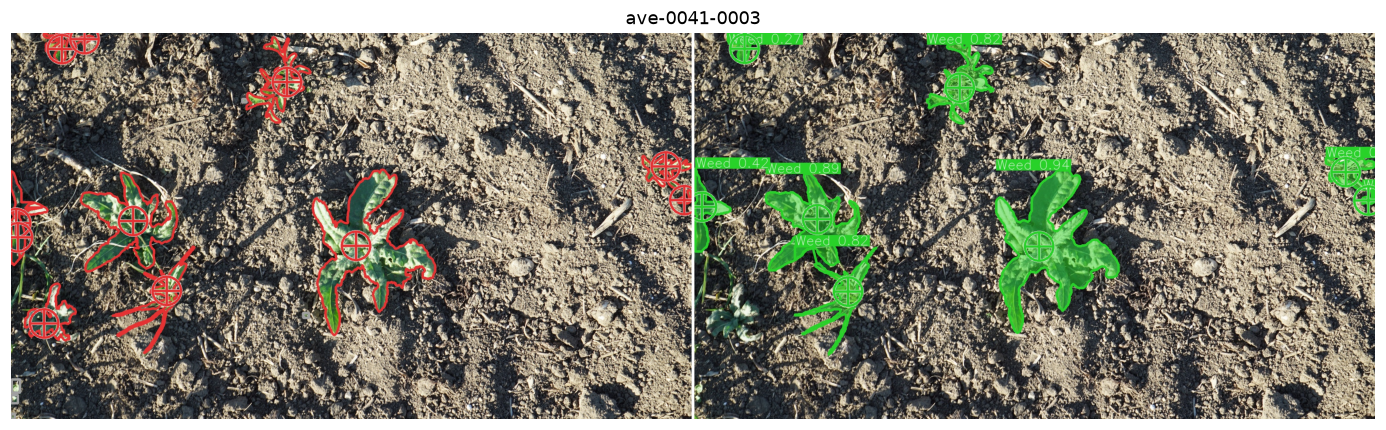

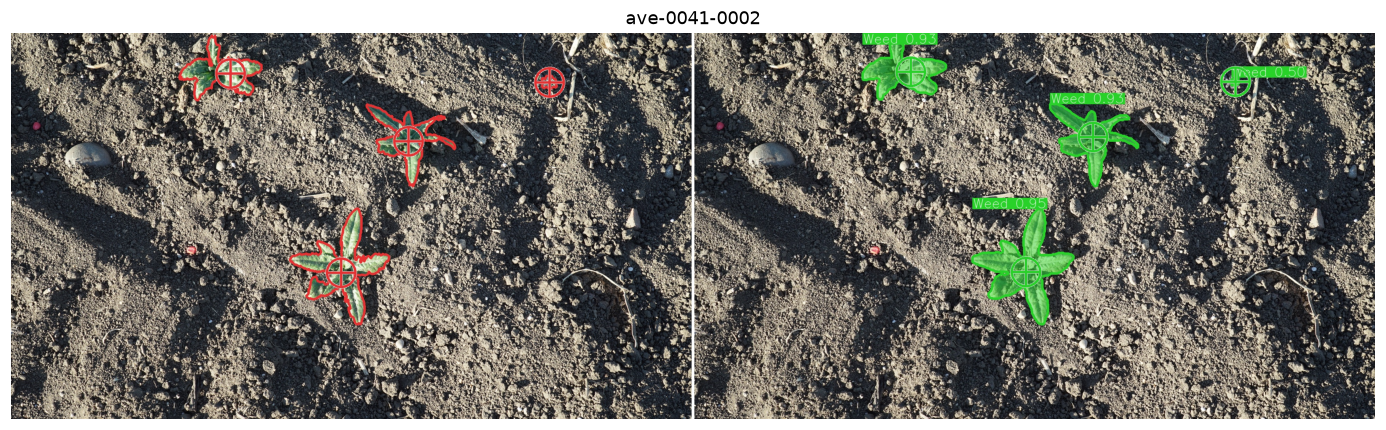

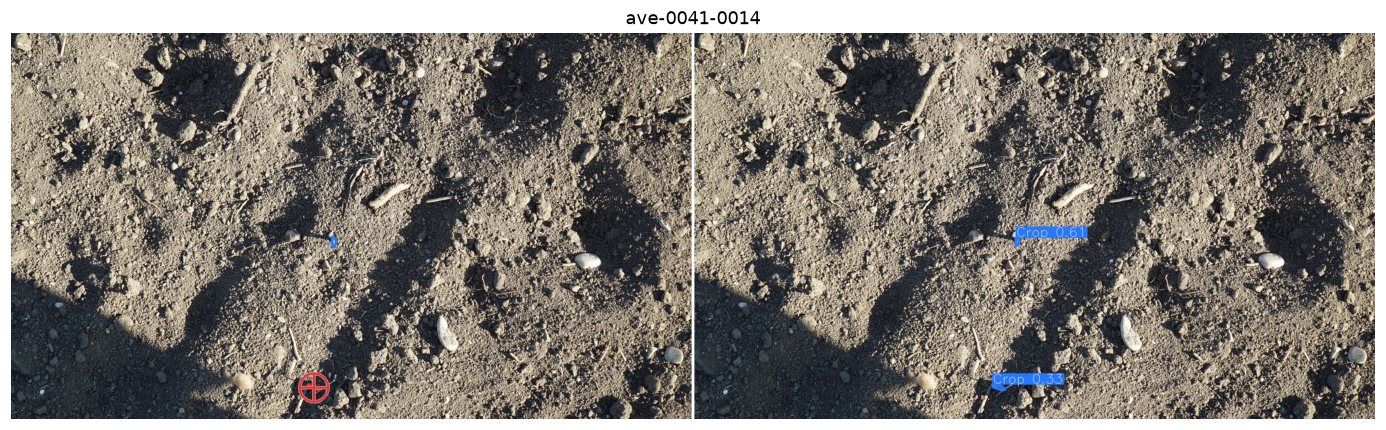

In [13]:
vis_dir = RUN_DIR / "eval" / "visualizations"
saved = sorted(p.stem for p in vis_dir.glob("*.jpg"))
display(img.set_index("image").loc[saved, ["gt_weeds", "gt_crops", "shots", "weeds_hit", "crop_hits"]])
SHOW = img.set_index("image").loc[saved].sort_values(["crop_hits", "gt_weeds"], ascending=False).index[:3]
for stem in SHOW:
    plt.figure(figsize=(16, 5))
    plt.imshow(cv2.cvtColor(cv2.imread(str(vis_dir / f"{stem}.jpg")), cv2.COLOR_BGR2RGB))
    plt.title(stem); plt.axis("off"); plt.show()

## 12. Conclusions for `yolo11s_seg_cropandweed`

Written from the numbers above for this run; re-read them if you point the notebook at another run.

1. **Training is healthy and finished.** Train and val losses fall together, val mAP plateaus from
   ~epoch 50, early stopping at 72 (best 52). More epochs of the same setup will not help.
2. **Crops are segmented well, weeds much less so** (mask mAP50-95 0.57 vs 0.26). In a laser
   setting this gives ~72 % of weeds destroyed and ~81 % of shots on a weed.
3. **Weeds are missed because they are small.** Weeds under ~24 px (~1 cm) are hit only ~60 %
   of the time vs 82-92 % for larger ones, and they cause about half of all misses. At
   `imgsz=1024` they are only ~10 px wide at the network input.
4. **Shots that miss mostly hit soil (~18 % of shots), not crops.** Soil and weed shots have
   overlapping confidences, so a higher `conf` removes weed shots as fast as soil shots. Some
   "soil" shots are likely unlabelled tiny weeds (worth checking in images).
5. **Crop damage (2.2 % of shots) is concentrated:** crop species 24 takes ~29 % shots per plant,
   and three Application-set sessions produce ~60 % of all crop hits. Almost all crop hits happen
   where the model failed to detect the crop, so the 20 px gate (3.3 % → 2.2 %) can't help more.
6. **The Application set (real fields) is much harder** than the Experimental set: lower hit rate
   and ~10× the crop hit rate. Results on real fields are what matter for deployment.
7. **Targeting method:** `center_weighted_dt` ≈ `distance_transform` > `skeleton` >> `centroid` >
   `box_center`; keep `center_weighted_dt` (it also aims closest to the plant centre).